# Лабораторная работа №3. Классическое машинное обучение в NLP

Тема: векторизация текстов, классификация, полнотекстовый поиск и тематическое моделирование.

Датасет тот же, что в лабораторных 1 и 2: AG News, 120 000 новостей четырёх классов (World, Sports, Business, Sci/Tech). Разбиение на Train и Test такое же: 80 на 20, стратифицированное, `random_state=42`.

План работы:
1. Векторизация: Bag of Words и TF-IDF, словарь строится только на Train.
2. Обучение двух классификаторов на TF-IDF: Naive Bayes и линейный SVM.
3. Оценка качества: macro-метрики, матрица ошибок, разбор пяти ошибок.
4. Инвертированный индекс по всему корпусу.
5. Поиск по формуле Okapi BM25.
6. Тематическая модель LDA, выбор числа тем по когерентности C_V, визуализация pyLDAvis.
7. Интерпретация тем.

In [1]:
import re, html, math, time, heapq, unicodedata, warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

RANDOM_STATE = 42
pd.set_option('display.max_colwidth', 120)

## 0. Данные и предобработка

Загружаю AG News и делаю то же разбиение, что в первых двух работах. Метки сдвигаю на единицу (1 World, 2 Sports, 3 Business, 4 Sci/Tech), как в задании. Если Hugging Face недоступен, ячейка берёт тот же датасет в виде CSV с GitHub.

In [2]:
LABEL_MAP = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}

try:
    from datasets import load_dataset
    raw = load_dataset('fancyzhx/ag_news')
    df = pd.DataFrame(raw['train'])
    df['label'] = df['label'] + 1
    source = 'Hugging Face'
except Exception as e:
    URL = 'https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/train.csv'
    df = pd.read_csv(URL, header=None, names=['label', 'title', 'description'])
    df['text'] = df['title'] + ' ' + df['description']
    source = 'GitHub CSV (запасной источник)'

df['category'] = df['label'].map(LABEL_MAP)

train_df, test_df = train_test_split(
    df[['text', 'label', 'category']], test_size=0.2,
    random_state=RANDOM_STATE, stratify=df['label'])
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print('Источник:', source)
print('Train:', train_df.shape, ' Test:', test_df.shape)
print('Среднее число слов в Train:', round(train_df['text'].str.split().str.len().mean(), 1))
print('Первый документ Train:', train_df['text'].iloc[0][:90])
print()
print(pd.concat([train_df['category'].value_counts().rename('Train'),
                 test_df['category'].value_counts().rename('Test')], axis=1))

Источник: GitHub CSV (запасной источник)
Train: (96000, 3)  Test: (24000, 3)


Среднее число слов в Train: 37.9
Первый документ Train: Clijsters Unsure About Latest Injury, Says Hewitt  TOKYO (Reuters) - Belgian Kim Clijsters

          Train  Test
category             
Sports    24000  6000
Sci/Tech  24000  6000
World     24000  6000
Business  24000  6000


Для всех следующих шагов нужен один и тот же очищенный текст. Беру правила из первой лабораторной: декодирую HTML-сущности (включая «потерянные» `#39;` и `quot;`), удаляю теги, заменяю ссылки, почту и числа на служебные токены, привожу текст к ASCII и разбиваю на токены. Отличия от первой работы: привожу всё к нижнему регистру, не добавляю `<s>` и `</s>` (они нужны только N-граммной модели), оставляю только токены с буквами (знаки препинания для классификации и поиска не нужны), а служебные токены записываю как обычные слова `num`, `url`, `email`.

In [3]:
RE_HTML_TAG = re.compile(r'<[^>]+>')
RE_ENTITY_NO_AMP = re.compile(r'(?<![&\w])(#\d+|#x[0-9a-fA-F]+|quot|amp|lt|gt|apos);')
RE_URL = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
RE_EMAIL = re.compile(r'\b[A-Za-z0-9._%+\-]+@[A-Za-z0-9.\-]+\.[A-Za-z]{2,}\b')
RE_NUMBER = re.compile(r'(?<![A-Za-z\-.,])\b\d+([.,]\d+)*\b(?![A-Za-z\-])')
RE_BACKSLASH = re.compile(r'\\+')
RE_TOKEN = re.compile(r'\[(?:NUM|URL|EMAIL)\]|\w+(?:[-.]\w+)*|[^\w\s]')
SERVICE = {'[NUM]': 'num', '[URL]': 'url', '[EMAIL]': 'email'}


def tokenize(text):
    """Очистка из лабораторной 1 + нижний регистр, без знаков препинания."""
    text = RE_ENTITY_NO_AMP.sub(r'&\1;', text)
    text = html.unescape(text)
    text = RE_HTML_TAG.sub(' ', text)
    text = RE_URL.sub('[URL]', text)
    text = RE_EMAIL.sub('[EMAIL]', text)
    text = unicodedata.normalize('NFKD', text).encode('ascii', errors='ignore').decode('ascii')
    text = RE_NUMBER.sub('[NUM]', text)
    text = RE_BACKSLASH.sub(' ', text)
    tokens = []
    for t in RE_TOKEN.findall(text):
        if t in SERVICE:
            tokens.append(SERVICE[t])
        elif re.search('[A-Za-z]', t):
            tokens.append(t.lower())
    return tokens


for d in (train_df, test_df):
    d['tokens'] = d['text'].map(tokenize)
    d['text_clean'] = d['tokens'].map(' '.join)

print(train_df['text'].iloc[1])
print(train_df['text_clean'].iloc[1])

Earthquake Swarm Shakes Eastern Sierra (AP) AP - A swarm of earthquakes  #151; one a magnitude-5.5  #151; jolted a remote, sparsely populated area along the eastern Sierra Nevada on Saturday, authorities said.
earthquake swarm shakes eastern sierra ap ap a swarm of earthquakes one a magnitude-5.5 jolted a remote sparsely populated area along the eastern sierra nevada on saturday authorities said


## 1. Статистическая векторизация

Строю две матрицы «документ на слово»:
- **Bag of Words**: в ячейке стоит число вхождений слова в документ;
- **TF-IDF**: то же число, но слово получает вес тем больше, чем реже оно встречается в корпусе. Использую сглаженный IDF из sklearn и логарифмирование частоты в документе (`sublinear_tf=True`), строки нормируются по длине.

Правило, которое здесь важно: словарь и IDF считаются **только на Train** (`fit_transform`), а Test только преобразуется (`transform`). Иначе информация о тестовых документах попала бы в признаки. Слова, которых нет в словаре Train, в тестовых векторах просто игнорируются. Слова, встретившиеся в Train менее чем в двух документах, отбрасываю (`min_df=2`): они не помогают обобщению и сильно раздувают словарь.

In [4]:
VEC_PARAMS = dict(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=2)

bow = CountVectorizer(**VEC_PARAMS)
tfidf = TfidfVectorizer(**VEC_PARAMS, sublinear_tf=True)

# fit только на Train, на Test только transform
X_train_bow = bow.fit_transform(train_df['text_clean'])
X_test_bow = bow.transform(test_df['text_clean'])
X_train_tfidf = tfidf.fit_transform(train_df['text_clean'])
X_test_tfidf = tfidf.transform(test_df['text_clean'])

def describe(name, X):
    nnz = X.nnz
    return {'матрица': name, 'форма': str(X.shape), 'ненулевых': nnz,
            'заполненность, %': round(100 * nnz / (X.shape[0] * X.shape[1]), 3),
            'слов в документе (в среднем)': round(nnz / X.shape[0], 1)}

pd.DataFrame([describe('BoW Train', X_train_bow), describe('BoW Test', X_test_bow),
              describe('TF-IDF Train', X_train_tfidf), describe('TF-IDF Test', X_test_tfidf)])

,матрица,форма,ненулевых,"заполненность, %",слов в документе (в среднем)
0,BoW Train,"(96000, 42500)",2957994,0.072,30.8
1,BoW Test,"(24000, 42500)",733230,0.072,30.6
2,TF-IDF Train,"(96000, 42500)",2957994,0.072,30.8
3,TF-IDF Test,"(24000, 42500)",733230,0.072,30.6


In [5]:
print('Размерность BoW   :', X_train_bow.shape[1])
print('Размерность TF-IDF:', X_train_tfidf.shape[1])
assert bow.get_feature_names_out().tolist() == tfidf.get_feature_names_out().tolist()

# доля слов тестовых документов, которых нет в словаре Train
vocab = set(bow.vocabulary_)
test_tokens = [t for toks in test_df['tokens'] for t in toks]
oov = sum(t not in vocab for t in test_tokens) / len(test_tokens)
print(f'Доля токенов Test вне словаря Train: {oov:.2%}')

Размерность BoW   : 42500
Размерность TF-IDF: 42500
Доля токенов Test вне словаря Train: 1.49%


### 1.1 От чего зависит размерность

Размерность задаёт не способ взвешивания, а то, какие слова попали в словарь. Чтобы это показать, строю словарь на Train при разных настройках токенизации и фильтрации.

In [6]:
configs = {
    'все слова (min_df=1)':                dict(min_df=1),
    'min_df=2 (используется дальше)':      dict(min_df=2),
    'min_df=5':                            dict(min_df=5),
    'min_df=2, без стоп-слов':             dict(min_df=2, stop_words='english'),
    'min_df=2, униграммы и биграммы':      dict(min_df=2, ngram_range=(1, 2)),
}
rows = []
for name, params in configs.items():
    v = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, **params)
    v.fit(train_df['text_clean'])
    rows.append({'настройки словаря': name, 'размерность': len(v.vocabulary_)})
pd.DataFrame(rows)

,настройки словаря,размерность
0,все слова (min_df=1),72749
1,min_df=2 (используется дальше),42500
2,min_df=5,24712
3,"min_df=2, без стоп-слов",42203
4,"min_df=2, униграммы и биграммы",372151


In [7]:
# один документ: какие слова BoW считает главными, а какие TF-IDF
i = 5
names = tfidf.get_feature_names_out()
row_bow, row_tfidf = X_train_bow[i].toarray().ravel(), X_train_tfidf[i].toarray().ravel()
print(train_df['text'].iloc[i][:200], '\n')
print('Топ-8 по BoW   :', [(str(names[j]), int(row_bow[j])) for j in np.argsort(-row_bow)[:8]])
print('Топ-8 по TF-IDF:', [(str(names[j]), round(float(row_tfidf[j]), 3)) for j in np.argsort(-row_tfidf)[:8]])

Virgin #39;s next destination: space LONDON Richard Branson, the adventurous entrepreneur behind the Virgin Group, said Monday that he would form a commercial space travel company that would start car 

Топ-8 по BoW   : [('would', 2), ('virgin', 2), ('that', 2), ('the', 2), ('space', 2), ('travel', 1), ('start', 1), ('said', 1)]
Топ-8 по TF-IDF: [('virgin', 0.371), ('adventurous', 0.315), ('destination', 0.273), ('space', 0.267), ('entrepreneur', 0.256), ('branson', 0.239), ('passengers', 0.22), ('would', 0.217)]


**Вывод по шагу 1.** BoW и TF-IDF дали матрицы одинаковой формы: 96 000 на 42 500 для Train и 24 000 на 42 500 для Test. Размерность определяют не веса, а словарь: он зависит от токенизации и фильтрации. Без отсечения редких слов в словаре Train 72 749 слов, из них 30 249 встречаются ровно в одном документе. Порог `min_df=2` оставляет 42 500 слов, `min_df=5` оставляет 24 712. Добавление биграмм раздувает пространство до 372 151 признака. Удаление стоп-слов почти ничего не меняет (минус 297 слов), потому что стоп-слов в английском языке мало, хотя на текст они приходятся в большом количестве.

Матрицы очень разрежены: ненулевых элементов 0,072%, в среднем 30,8 разных слов на документ, поэтому они хранятся в разреженном формате. На Test словарь Train не покрывает 1,49% токенов: эти слова в тестовых векторах игнорируются, это и есть цена правила «fit только на Train».

На примере документа видна разница между схемами. BoW считает главными служебные слова (`would`, `that`, `the` по два вхождения), TF-IDF выдвигает содержательные: `virgin` (0,371), `adventurous`, `destination`, `space`, `entrepreneur`, `branson`. Поэтому дальше используется TF-IDF.

## 2. Обучение классификаторов

Целевая задача: определение категории новости (4 класса). Беру два классических алгоритма на TF-IDF векторах:
- **Multinomial Naive Bayes**: считает вероятность класса по частотам слов, предполагая, что слова независимы. Очень быстрый, хорошо работает на текстах.
- **Линейный SVM (`LinearSVC`)**: ищет гиперплоскости, максимально разделяющие классы в пространстве слов. На разреженных TF-IDF признаках обычно сильнее Naive Bayes.

Сначала проверяю баланс классов.

In [8]:
y_train = train_df['label'].values
y_test = test_df['label'].values
classes = np.array([1, 2, 3, 4])

print('Доли классов в Train:', (pd.Series(y_train).value_counts(normalize=True).sort_index()).round(3).to_dict())
print('Веса class_weight="balanced":', {int(c): round(float(w), 3) for c, w in zip(classes, compute_class_weight('balanced', classes=classes, y=y_train))})

Доли классов в Train: {1: 0.25, 2: 0.25, 3: 0.25, 4: 0.25}
Веса class_weight="balanced": {1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0}


Классы сбалансированы идеально (по 25%), поэтому веса при `class_weight='balanced'` равны единице, и настройка ничего не меняет. Я всё равно оставляю её в SVM: если этот код применят к несбалансированным данным, балансировка сработает сама. У Naive Bayes эквивалент это априорные вероятности классов, при равных долях они равны.

Гиперпараметры подбираю кросс-валидацией на Train (3 фолда, метрика macro F1). Тест в подборе не участвует. Векторизатор вынесен внутрь пайплайна, поэтому в каждом фолде словарь и IDF считаются только на обучающей части фолда.

In [9]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def make_pipe(clf):
    return Pipeline([('tfidf', TfidfVectorizer(**VEC_PARAMS, sublinear_tf=True)), ('clf', clf)])

t0 = time.time()
nb_search = GridSearchCV(make_pipe(MultinomialNB()), {'clf__alpha': [0.03, 0.1, 0.3, 1.0]},
                         scoring='f1_macro', cv=cv, n_jobs=2).fit(train_df['text_clean'], y_train)
svm_search = GridSearchCV(make_pipe(LinearSVC(class_weight='balanced', random_state=RANDOM_STATE)),
                          {'clf__C': [0.1, 0.3, 1.0, 3.0]},
                          scoring='f1_macro', cv=cv, n_jobs=2).fit(train_df['text_clean'], y_train)
print(f'Подбор занял {time.time() - t0:.0f} с\n')

for name, s, key in [('Naive Bayes', nb_search, 'clf__alpha'), ('LinearSVC', svm_search, 'clf__C')]:
    print(name)
    print(pd.DataFrame({key.split('__')[1]: s.cv_results_['param_' + key],
                        'macro F1 (CV)': s.cv_results_['mean_test_score'].round(4)}).to_string(index=False))
    print('Лучшее:', s.best_params_, '\n')

Подбор занял 42 с

Naive Bayes
 alpha  macro F1 (CV)
  0.03         0.9028
  0.10         0.9033
  0.30         0.9028
  1.00         0.9010
Лучшее: {'clf__alpha': 0.1} 

LinearSVC
  C  macro F1 (CV)
0.1         0.9114
0.3         0.9148
1.0         0.9118
3.0         0.9022
Лучшее: {'clf__C': 0.3} 



In [10]:
nb = MultinomialNB(alpha=nb_search.best_params_['clf__alpha'])
svm = LinearSVC(C=svm_search.best_params_['clf__C'], class_weight='balanced', random_state=RANDOM_STATE)

t0 = time.time(); nb.fit(X_train_tfidf, y_train); t_nb = time.time() - t0
t0 = time.time(); svm.fit(X_train_tfidf, y_train); t_svm = time.time() - t0
print(f'Naive Bayes обучен за {t_nb:.2f} с, LinearSVC за {t_svm:.2f} с')

Naive Bayes обучен за 0.03 с, LinearSVC за 2.68 с


**Вывод по шагу 2.** Классы сбалансированы, поэтому балансировка весов ничего не меняет (все веса равны 1,0). По кросс-валидации на Train лучше всех оказались `alpha=0,1` для Naive Bayes (macro F1 0,9033, при этом весь диапазон от 0,03 до 1,0 даёт 0,9010-0,9033, то есть модель почти не чувствительна к параметру) и `C=0,3` для LinearSVC (0,9148). У SVM зависимость заметнее: при слишком большом `C=3` качество падает до 0,9022, модель начинает подстраиваться под обучающие данные. Naive Bayes обучается за 0,04 с, LinearSVC за 2,9 с: оба алгоритма очень быстрые на разреженных данных.

## 3. Оценка качества классификации

Предсказываю метки на тестовой выборке и считаю macro-метрики: Precision, Recall и F1 считаются отдельно по каждому классу, затем усредняются, и все классы входят с одинаковым весом. Accuracy добавляю в таблицу только для сравнения.

In [11]:
pred = {'Naive Bayes': nb.predict(X_test_tfidf), 'LinearSVC': svm.predict(X_test_tfidf)}

rows = []
for name, p in pred.items():
    P, R, F, _ = precision_recall_fscore_support(y_test, p, average='macro')
    rows.append({'модель': name, 'Macro Precision': P, 'Macro Recall': R, 'Macro F1': F,
                 'Accuracy': accuracy_score(y_test, p)})
metrics = pd.DataFrame(rows).set_index('модель').round(4)
display(metrics)

target_names = [LABEL_MAP[c] for c in classes]
for name, p in pred.items():
    print(name)
    print(classification_report(y_test, p, target_names=target_names, digits=4))

,Macro Precision,Macro Recall,Macro F1,Accuracy
модель,,,,
Naive Bayes,0.9087,0.9088,0.9086,0.9088
LinearSVC,0.9226,0.9227,0.9225,0.9227


Naive Bayes
              precision    recall  f1-score   support

       World     0.9212    0.8960    0.9084      6000
      Sports     0.9566    0.9802    0.9682      6000
    Business     0.8807    0.8697    0.8751      6000
    Sci/Tech     0.8762    0.8895    0.8828      6000

    accuracy                         0.9088     24000
   macro avg     0.9087    0.9088    0.9086     24000
weighted avg     0.9087    0.9088    0.9086     24000

LinearSVC
              precision    recall  f1-score   support

       World     0.9387    0.9038    0.9209      6000
      Sports     0.9562    0.9870    0.9714      6000
    Business     0.8949    0.8940    0.8944      6000
    Sci/Tech     0.9006    0.9060    0.9033      6000

    accuracy                         0.9227     24000
   macro avg     0.9226    0.9227    0.9225     24000
weighted avg     0.9226    0.9227    0.9225     24000



**Таблица метрик и почему Accuracy не показательна.** LinearSVC лучше Naive Bayes по всем метрикам: Macro F1 0,9225 против 0,9086, то есть на 1,4 процентного пункта. Лучше всего классифицируется Sports (F1 0,971), хуже всего Business (0,894) и Sci/Tech (0,903). Naive Bayes отстаёт сильнее всего на этих же двух классах.

Задание просит обосновать, почему Accuracy не репрезентативна. Главный классический довод (при дисбалансе модель, всегда выдающая большинство, получает высокую Accuracy) на AG News не работает: в Test по 6 000 документов каждого класса. Это видно по таблице: Accuracy (0,9227) совпадает с Macro Recall (0,9227), при равных классах эти метрики математически одинаковы. Поэтому доводы другие:

1. Одно число скрывает различия между классами: общая доля верных ответов 92,3% складывается из 97,1% F1 у Sports и 89,4% у Business.
2. Accuracy не показывает, какие ошибки совершает модель. Путать Business с Sci/Tech и путать World со Sports это разные ошибки с разной ценой для пользователя новостной ленты.
3. Accuracy зависит от пропорций классов в выборке. В реальном потоке новостей классы встречаются не поровну, и Accuracy тогда определялась бы долей лёгких классов. Macro-метрики усредняют по классам с равным весом и не зависят от пропорций.

Поэтому основной метрикой беру Macro F1, а Accuracy указываю только для справки.

**Матрица ошибок.** Основная путаница у LinearSVC происходит между Business и Sci/Tech: 7,0% бизнес-новостей уходят в Sci/Tech и 6,2% наоборот (423 и 374 документа). Следом идут World, которые модель относит к Business (4,0%, 241 документ) и Sports (3,0%, 180 документов). Sports почти не путается с остальными: 98,7% верных ответов.

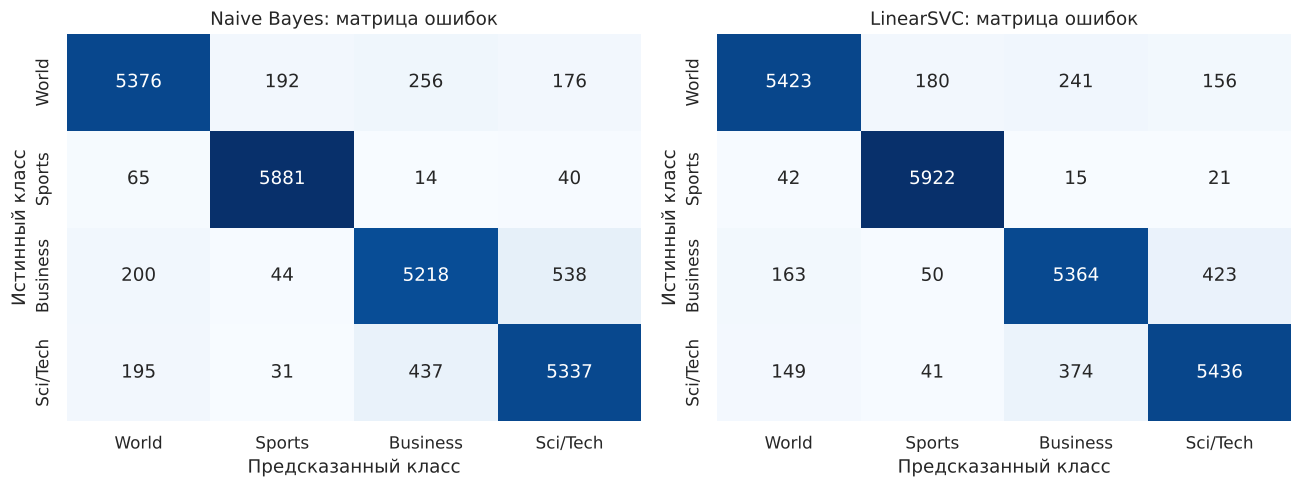

LinearSVC, доля ответов по каждому истинному классу, %:
          World  Sports  Business  Sci/Tech
World      90.4     3.0       4.0       2.6
Sports      0.7    98.7       0.2       0.4
Business    2.7     0.8      89.4       7.0
Sci/Tech    2.5     0.7       6.2      90.6


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, (name, p) in zip(axes, pred.items()):
    cm = confusion_matrix(y_test, p, labels=classes)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=target_names, yticklabels=target_names)
    ax.set_title(f'{name}: матрица ошибок')
    ax.set_xlabel('Предсказанный класс'); ax.set_ylabel('Истинный класс')
plt.tight_layout(); plt.show()

cm_svm = confusion_matrix(y_test, pred['LinearSVC'], labels=classes)
print('LinearSVC, доля ответов по каждому истинному классу, %:')
print(pd.DataFrame((100 * cm_svm / cm_svm.sum(axis=1, keepdims=True)).round(1),
                   index=target_names, columns=target_names))

### 3.1 Анализ ошибок (Error Analysis)

Разбираю лучшую модель, LinearSVC. Беру пять самых частых типов ошибок (пара «истинный класс и предсказанный класс») и для каждой пары случайно выбираю один пример. Для каждого примера показываю слова, которые больше всего «потянули» решение к предсказанному классу и к истинному. Вклад слова в оценку класса это вес слова в модели, умноженный на его TF-IDF в этом документе.

In [13]:
feat = tfidf.get_feature_names_out()
coef = {c: svm.coef_[k] for k, c in enumerate(svm.classes_)}
p_svm = pred['LinearSVC']
err_idx = np.where(p_svm != y_test)[0]
print(f'LinearSVC ошибся на {len(err_idx)} из {len(y_test)} тестовых документов ({len(err_idx)/len(y_test):.2%})\n')

top_pairs = Counter(zip(y_test[err_idx], p_svm[err_idx])).most_common(5)
rng = np.random.RandomState(RANDOM_STATE)

examples = []
for n, ((t, p), cnt) in enumerate(top_pairs, 1):
    pool = [i for i in err_idx if y_test[i] == t and p_svm[i] == p]
    i = int(rng.choice(pool))
    x = X_test_tfidf[i].toarray().ravel()
    for_pred = x * coef[p]
    for_true = x * coef[t]
    top_pred = [(str(feat[j]), round(float(for_pred[j]), 2)) for j in np.argsort(-for_pred)[:6]]
    top_true = [(str(feat[j]), round(float(for_true[j]), 2)) for j in np.argsort(-for_true)[:4]]
    examples.append(i)
    print(f'Пример {n}. Истина: {LABEL_MAP[t]}, предсказано: {LABEL_MAP[p]} (таких ошибок {cnt})')
    print('Текст:', test_df['text'].iloc[i][:420])
    print('Слова за предсказанный класс:', top_pred)
    print('Слова за истинный класс    :', top_true)
    print()

LinearSVC ошибся на 1855 из 24000 тестовых документов (7.73%)

Пример 1. Истина: Business, предсказано: Sci/Tech (таких ошибок 423)
Текст: Update 1: EBay Shuffles Positions of 3 Executives EBay Inc. said Thursday that it shuffled the positions of three senior vice presidents, promoting each in title and creating new heads for PayPal, eBay International and eBay North America.
Слова за предсказанный класс: [('ebay', 0.58), ('positions', 0.16), ('paypal', 0.16), ('vice', 0.09), ('heads', 0.05), ('executives', 0.05)]
Слова за истинный класс    : [('america', 0.11), ('update', 0.11), ('executives', 0.11), ('inc', 0.09)]

Пример 2. Истина: Sci/Tech, предсказано: Business (таких ошибок 374)
Текст: Policy to Preserve Coastline Runs Into Reality on Nation's Beaches Property owners at Cape San Blas, Fla., have run into an insurance Catch-22.
Слова за предсказанный класс: [('insurance', 0.45), ('property', 0.18), ('nation', 0.11), ('owners', 0.06), ('san', 0.06), ('reality', 0.05)]
Слова за исти

**Вывод по анализу ошибок.** LinearSVC ошибся на 1 855 из 24 000 документов (7,73%). Пять разобранных примеров показывают разные причины.

1. **Граница между Business и Sci/Tech (пример с eBay).** Новость о перестановках в руководстве eBay по сути деловая, но слово `ebay` (вклад 0,58) в обучающих данных встречается в 195 документах, из них 140 (72%) в Sci/Tech, а `paypal` в 53 документах из 63. Модель следует за этими словами. Интернет-компании в AG News относят то к бизнесу, то к технологиям, поэтому граница классов размыта и сама по себе.
2. **Спорная разметка (пример про береговую линию и страховку).** Истинная метка Sci/Tech, но заметка о страховании владельцев недвижимости по смыслу похожа на деловую, и слова `insurance` (0,45) и `property` уводят её в Business: слово `insurance` в обучающих данных в 89% случаев (429 из 483) относится к Business. Это скорее шум в разметке, чем ошибка модели.
3. **Слово без учёта контекста (ураган Фрэнсис и «Labor Day»).** Истина World, предсказан Business. Мешок слов видит `labor` (в обучающих данных 285 из 511 документов с этим словом относятся к Business), но не понимает, что Labor Day это праздник, а не трудовая тема. Модель не учитывает порядок и смысл слов. Кроме того, локальная американская новость с меткой World для модели нетипична.
4. **Многозначность слова (похороны балерины Маркововой).** Истина World, предсказан Sports. Самый сильный вклад даёт слово `dame` (0,30): в обучающих данных оно встречается в 225 документах, и 223 из них Sports (в 99% это команда Notre Dame). Здесь это титул «дама».
5. **Спорная разметка и тематический шум (подарок священника на образование).** Истина Business, предсказан World. Слова `church`, `death`, `people`, `students` относятся к общественной теме, а деловая сторона заметки (сумма в 575 000 долларов, фонд) в словаре почти не представлена. Метка Business здесь спорна.

Итого: две ошибки связаны с неоднозначной границей классов, две с шумом в разметке и одна со слепотой мешка слов к контексту и многозначности. Улучшить результат можно признаками, которые учитывают порядок слов (биграммы, эмбеддинги), и чисткой разметки.

## 4. Построение инвертированного индекса

Инвертированный индекс это словарь «слово: список номеров документов, где оно встречается». Он позволяет не перебирать весь корпус при поиске: по слову запроса сразу видно, в каких документах его искать. Индекс строю по всему корпусу, Train и Test вместе, 120 000 документов, и присваиваю каждому сквозной номер `doc_id`.

Для поиска слова нужно привести к одной форме, поэтому после токенизации я удаляю стоп-слова и служебные токены (`num`, `url`, `email`) и делаю стемминг Snowball: тогда `prices` и `price` попадут в один список. Стемминг выбран вместо лемматизации, потому что он быстрый и работает без внешних моделей. Сам индекс хранит только номера документов, как требует задание. Частоты слов в документах для BM25 хранятся отдельно (`doc_tf`).

In [14]:
from nltk.stem.snowball import SnowballStemmer

corpus_df = pd.concat([train_df, test_df], ignore_index=True)   # doc_id = номер строки
print('Документов в корпусе:', len(corpus_df))

STOP = set(ENGLISH_STOP_WORDS) | {'num', 'url', 'email'}
stemmer = SnowballStemmer('english')
stem_cache = {t: stemmer.stem(t) for t in set(t for toks in corpus_df['tokens'] for t in toks)}

def analyze(tokens):
    """Токены в термы индекса: без стоп-слов, со стеммингом."""
    return [stem_cache.get(t) or stemmer.stem(t) for t in tokens if t not in STOP and len(t) > 1]

t0 = time.time()
search_tokens = [analyze(toks) for toks in corpus_df['tokens']]

inverted_index = defaultdict(list)   # терм -> список doc_id
doc_tf = []                          # для каждого документа: сколько раз встретился каждый терм
for doc_id, terms in enumerate(search_tokens):
    counts = Counter(terms)
    doc_tf.append(counts)
    for term in counts:
        inverted_index[term].append(doc_id)    # doc_id идут по возрастанию, списки отсортированы

doc_len = np.array([len(t) for t in search_tokens])
print(f'Индекс построен за {time.time() - t0:.1f} с')
print('Уникальных термов:', len(inverted_index))
print('Всего записей в списках:', sum(map(len, inverted_index.values())))
print('Средняя длина документа после фильтрации:', round(doc_len.mean(), 1), 'термов')

Документов в корпусе: 120000


Индекс построен за 2.1 с
Уникальных термов: 60407
Всего записей в списках: 2376430
Средняя длина документа после фильтрации: 23.2 термов


In [15]:
for term in ['oil', 'olymp', 'microsoft']:
    ids = inverted_index[term]
    print(f"'{term}': {len(ids)} документов, первые номера {ids[:8]}")

longest = sorted(inverted_index.items(), key=lambda kv: -len(kv[1]))[:8]
print('\nСамые длинные списки:', [(t, len(ids)) for t, ids in longest])
print('Термов, встречающихся ровно в одном документе:', sum(len(v) == 1 for v in inverted_index.values()))

'oil': 4139 документов, первые номера [109, 238, 264, 332, 371, 427, 513, 586]
'olymp': 2103 документов, первые номера [15, 83, 126, 146, 167, 203, 361, 397]
'microsoft': 3699 документов, первые номера [38, 110, 124, 200, 202, 217, 271, 275]

Самые длинные списки: [('said', 19673), ('new', 17861), ('reuter', 12958), ('year', 10030), ('compani', 9276), ('ap', 8481), ('say', 8229), ('world', 7568)]
Термов, встречающихся ровно в одном документе: 26894


**Вывод по шагу 4.** По 120 000 документов получилось 60 407 уникальных термов и 2 376 430 записей в списках. Средний документ после фильтрации содержит 23,2 терма. Распределение длин списков сильно скошено: 26 894 терма (44,5%) встречаются в единственном документе, а самые длинные списки у общих слов: `said` (19 673 документа), `new`, `reuter`, `year`, `compani`, `ap`. Редкие слова, в основном имена и опечатки, дают очень короткие списки, поэтому поиск по ним мгновенный.

Главная польза индекса видна в шаге 5: вместо проверки всех 120 000 документов поиск берёт только документы из списков слов запроса, например 10 706 для запроса про нефть (8,9% корпуса) и 2 862 для запроса про Олимпиаду (2,4%).

## 5. Поисковый движок BM25

Okapi BM25 оценивает релевантность документа D запросу Q как сумму по словам запроса:

`score(D, Q) = сумма по термам q из Q: IDF(q) * tf(q, D) * (k1 + 1) / (tf(q, D) + k1 * (1 - b + b * |D| / avgdl))`

- `tf(q, D)` сколько раз терм встречается в документе;
- `IDF(q) = ln(1 + (N - n + 0.5) / (n + 0.5))`, где N число документов, n число документов с термом: редкие слова весят больше;
- `|D|` длина документа, `avgdl` средняя длина: длинные документы штрафуются;
- `k1 = 1.5` ограничивает рост от повторов слова, `b = 0.75` задаёт силу учёта длины.

Функция принимает произвольный запрос, превращает его в термы тем же способом, что и документы, берёт кандидатов из инвертированного индекса (все документы, где есть хотя бы один терм запроса) и ранжирует их по формуле.

In [16]:
N = len(search_tokens)
avgdl = doc_len.mean()
idf = {t: math.log(1 + (N - len(ids) + 0.5) / (len(ids) + 0.5)) for t, ids in inverted_index.items()}

def bm25_search(query, top_k=5, k1=1.5, b=0.75):
    terms = list(dict.fromkeys(analyze(tokenize(query))))       # уникальные термы запроса
    scores = defaultdict(float)
    for t in terms:
        if t not in inverted_index:
            continue
        for d in inverted_index[t]:                              # только документы из списка терма
            tf = doc_tf[d][t]
            scores[d] += idf[t] * tf * (k1 + 1) / (tf + k1 * (1 - b + b * doc_len[d] / avgdl))
    return heapq.nlargest(top_k, scores.items(), key=lambda kv: kv[1]), terms, len(scores)

def show(query, expected=None, top_k=5):
    top, terms, n_cand = bm25_search(query, top_k)
    print(f"Запрос: '{query}'  ->  термы {terms}, кандидатов: {n_cand}")
    res = pd.DataFrame([{'место': r, 'doc_id': d, 'BM25': round(s, 2), 'класс': corpus_df['category'][d],
                         'текст': corpus_df['text'][d][:130]} for r, (d, s) in enumerate(top, 1)])
    display(res)
    if expected:
        hit = (res['класс'] == expected).mean()
        print(f'Доля результатов класса {expected}: {hit:.0%}\n')

show('oil prices record high', 'Business')
show('olympic gold medal swimming', 'Sports')
show('microsoft security software update', 'Sci/Tech')

Запрос: 'oil prices record high'  ->  термы ['oil', 'price', 'record', 'high'], кандидатов: 10706


,место,doc_id,BM25,класс,текст
0,1,16959,21.45,Business,Oil Prices Rebound Towards Record Highs Oil prices moved back towards record highs tonight amid continued concerns o...
1,2,87065,20.97,Business,"Oil Prices Rise Toward \$52 a Barrel, Set Another Record High Oil prices hit record highs again Wednesday, amid cont..."
2,3,86373,20.83,Business,Oil Prices Nudge Record High Oil prices were hovering close to last weeks record high today after breaking through t...
3,4,88575,20.76,Business,Oil Prices Again Hit Record Highs in US Oil prices have hit record highs in the United States for the third straight...
4,5,18648,20.53,Business,"World oil prices rise to another record high NEW YORK, October 18 (newratings.com) - Crude oil prices increased to n..."


Доля результатов класса Business: 100%

Запрос: 'olympic gold medal swimming'  ->  термы ['olymp', 'gold', 'medal', 'swim'], кандидатов: 2862


,место,doc_id,BM25,класс,текст
0,1,62620,25.39,Sports,"Swimming: Phelps Wins Fifth Gold, Seventh Medal ATHENS (Reuters) - Michael Phelps clinched his fifth gold medal an..."
1,2,22354,24.91,Sports,"Swimming: Fifth Gold, Seventh Medal for Phelps ATHENS (Reuters) - Michael Phelps won his fifth gold medal at the A..."
2,3,62168,24.91,Sports,"Two golds make Phelps #39; day Michael Phelps showed no signs of either yesterday, swimming to two gold medals in th..."
3,4,27035,24.42,Sports,Phelps targets six golds Michael Phelps will bid to repeat his feat of six Olympic gold medals when he competes in t...
4,5,16647,23.64,Sports,Michael Phelps Wins 6 Gold Medals in Swimming in Athens The eight days of Olympic swimming competition ended Saturda...


Доля результатов класса Sports: 100%



Запрос: 'microsoft security software update'  ->  термы ['microsoft', 'secur', 'softwar', 'updat'], кандидатов: 11756


,место,doc_id,BM25,класс,текст
0,1,103701,18.27,Sci/Tech,"New flaws found in Microsoft security (AFP) AFP - Internet security experts have found two ""flaws"" with Microsoft Co..."
1,2,6168,18.24,Sci/Tech,"Microsoft delays security update for Windows XP Professional REDMOND, Wash. -- Microsoft has delayed distribution of..."
2,3,29942,17.99,Sci/Tech,"Microsoft security updates Microsoft has released fresh security updates for Office, and an update to its MSN messen..."
3,4,22283,17.98,Sci/Tech,Microsoft distributes XP security update Microsoft says it has distributed about 106 million copies of its major sec...
4,5,81527,17.11,Sci/Tech,Microsoft to help users prepare for patching Microsoft has promised to give advance notice of its monthly security u...


Доля результатов класса Sci/Tech: 100%



In [17]:
# проверка реализации: пересчёт оценки лучшего документа напрямую, не через индекс
query = 'microsoft security software update'
top, terms, _ = bm25_search(query, 1)
d, s_index = top[0]
manual = 0.0
for t in terms:
    n_t = sum(1 for c in doc_tf if t in c)                      # документная частота прямым перебором
    tf = search_tokens[d].count(t)
    if tf:
        manual += math.log(1 + (N - n_t + 0.5) / (n_t + 0.5)) * tf * 2.5 / (tf + 1.5 * (0.25 + 0.75 * len(search_tokens[d]) / avgdl))
print(f'Оценка через индекс: {s_index:.6f}, пересчёт напрямую: {manual:.6f}')
assert abs(s_index - manual) < 1e-9

print('Запрос из слов, которых нет в корпусе:', bm25_search('zzzxqv qwertyuiop')[0])

Оценка через индекс: 18.269065, пересчёт напрямую: 18.269065
Запрос из слов, которых нет в корпусе: []


**Вывод по шагу 5.** Все три запроса дали ожидаемый результат: в топ-5 по запросу про нефть пять статей Business с заголовками про рекордные цены, по запросу про плавание пять спортивных новостей про Майкла Фелпса на Олимпиаде в Афинах, по запросу про Microsoft пять статей Sci/Tech про безопасность и обновления Windows. По классу точность в топ-5 равна 100% в каждом случае. Это грубая оценка (она показывает только соответствие класса темe запроса, а не релевантность каждой статьи), но она подтверждает, что ранжирование работает.

Реализацию я проверила отдельно: оценка лучшего документа, посчитанная напрямую по формуле без индекса, совпала с оценкой поисковой функции (18,269065). Запрос из несуществующих слов возвращает пустой результат.

Ограничения: поиск работает по принципу ИЛИ (подходит документ с любым словом запроса, но чем больше слов, тем выше оценка), порядок слов и фразы не учитываются, синонимы не распознаются, а стемминг иногда даёт неочевидные формы (`olymp`, `secur`).

## 6. Тематическое моделирование (LDA)

LDA предполагает, что каждый документ это смесь тем, а каждая тема это распределение вероятностей по словам. Алгоритм по частотам слов восстанавливает обе части без разметки. Число тем K нужно задать заранее, поэтому его подбираю по метрике когерентности C_V: она оценивает, насколько часто топ-слова одной темы встречаются рядом в текстах, то есть насколько тема «связная». Чем выше, тем лучше.

### 6.1 Подготовка корпуса

Для LDA нужны только слова, несущие тематику. Лемматизирую тексты spaCy (так слова разных форм не дробят тему) и оставляю существительные, имена собственные, прилагательные и глаголы. Убираю стоп-слова и служебные слова газетного шаблона и общие глаголы вроде `say` и `make`, которые встречаются в любой теме. Из словаря удаляю слова, которые встречаются меньше чем в 15 документах или больше чем в 20% документов.

Обучение LDA на 120 000 документах для десятка значений K заняло бы слишком много времени, поэтому работаю со случайной выборкой в 20 000 документов (Train и Test вместе). Метки классов при этом не используются.

In [18]:
import spacy
from gensim.corpora import Dictionary
from gensim.models import LdaMulticore, CoherenceModel

nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])

def light_clean(text):
    """Мягкая очистка для spaCy: регистр сохраняем, он нужен тэггеру."""
    text = RE_ENTITY_NO_AMP.sub(r'&\1;', text)
    text = html.unescape(text)
    text = RE_HTML_TAG.sub(' ', text)
    text = RE_URL.sub(' ', text)
    text = unicodedata.normalize('NFKD', text).encode('ascii', errors='ignore').decode('ascii')
    return RE_BACKSLASH.sub(' ', text)

lda_df = corpus_df.sample(20000, random_state=RANDOM_STATE).reset_index(drop=True)

KEEP_POS = {'NOUN', 'PROPN', 'ADJ', 'VERB'}
LDA_STOP = set(ENGLISH_STOP_WORDS) | {
    'reuters', 'ap', 'afp', 'say', 'tell', 'new', 'year', 'week', 'month', 'day', 'yesterday',
    'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday',
    'inc', 'corp', 'co', 'ltd', 'mr', 'include', 'make', 'take', 'get', 'go', 'come', 'see',
    'use', 'know', 'want', 'plan', 'time', 'report', 'lead', 'end', 'high', 'open', 'people', 'group'}

t0 = time.time()
lda_texts = []
for doc in nlp.pipe((light_clean(t) for t in lda_df['text']), batch_size=500, n_process=2):
    lda_texts.append([w.lemma_.lower() for w in doc
                      if w.pos_ in KEEP_POS and w.lemma_.isalpha() and len(w.lemma_) >= 3
                      and w.lemma_.lower() not in LDA_STOP])
print(f'Лемматизация заняла {time.time() - t0:.0f} с')

dictionary = Dictionary(lda_texts)
dictionary.filter_extremes(no_below=15, no_above=0.2)
corpus = [dictionary.doc2bow(d) for d in lda_texts]
keep = [i for i, bow_ in enumerate(corpus) if len(bow_) >= 3]       # документы, где осталось хотя бы 3 слова
corpus = [corpus[i] for i in keep]
lda_texts = [[w for w in lda_texts[i] if w in dictionary.token2id] for i in keep]
lda_df = lda_df.iloc[keep].reset_index(drop=True)

print('Документов для LDA:', len(corpus))
print('Размер словаря:', len(dictionary))
print('Среднее число слов в документе:', round(np.mean([len(d) for d in lda_texts]), 1))
print('Пример:', lda_texts[0])

Лемматизация заняла 37 с


Документов для LDA: 19990
Размер словаря: 3736
Среднее число слов в документе: 16.4
Пример: ['czech', 'door', 'toronto', 'martin', 'team', 'sit', 'morning', 'canada', 'choose', 'bow', 'night', 'world', 'cup', 'hockey', 'semi', 'final', 'victory', 'czech', 'republic', 'left', 'injury']


### 6.2 Перебор числа тем и когерентность C_V

Для каждого K из сетки обучаю модель LDA и считаю C_V по топ-10 словам каждой темы. Использую пакетный режим обучения (`batch=True`): он медленнее онлайн-режима, но на коротких новостях даёт заметно более чистые темы (в онлайн-режиме у меня одна из четырёх тем получалась смешанной). Параметры `alpha` и `eta` оставляю по умолчанию, то есть симметричными.

Результат LDA зависит от случайной инициализации: при одном и том же K коэффициент когерентности у разных запусков заметно различается. Поэтому для каждого K обучаю две модели с разным `random_state` и сравниваю среднюю когерентность. Сетку K ограничиваю значением 12, так как в датасете четыре класса, а время обучения растёт с K.

In [19]:
K_GRID = [2, 3, 4, 5, 6, 8, 10, 12]
SEEDS = [42, 7]
models, rows = {}, []

for K in K_GRID:
    for seed in SEEDS:
        t0 = time.time()
        m = LdaMulticore(corpus, id2word=dictionary, num_topics=K, workers=2, batch=True, chunksize=2500,
                         passes=12, iterations=50, random_state=seed)
        cm = CoherenceModel(model=m, texts=lda_texts, dictionary=dictionary, coherence='c_v', topn=10, processes=2)
        models[(K, seed)] = m
        rows.append({'K': K, 'seed': seed, 'C_V': cm.get_coherence(), 'секунд': round(time.time() - t0)})
        print(f'K={K:>2}  seed={seed:>2}  C_V={rows[-1]["C_V"]:.4f}  ({rows[-1]["секунд"]} с)', flush=True)

coh_all = pd.DataFrame(rows)
coh = coh_all.groupby('K')['C_V'].agg(['mean', 'min', 'max']).reset_index()

K= 2  seed=42  C_V=0.3459  (52 с)


K= 2  seed= 7  C_V=0.3780  (48 с)


K= 3  seed=42  C_V=0.3535  (49 с)


K= 3  seed= 7  C_V=0.5165  (52 с)


K= 4  seed=42  C_V=0.4740  (51 с)


K= 4  seed= 7  C_V=0.6597  (49 с)


... (6 outputs left out)

K=10  seed=42  C_V=0.4801  (39 с)


K=10  seed= 7  C_V=0.5035  (41 с)


K=12  seed=42  C_V=0.4574  (41 с)


K=12  seed= 7  C_V=0.5126  (43 с)


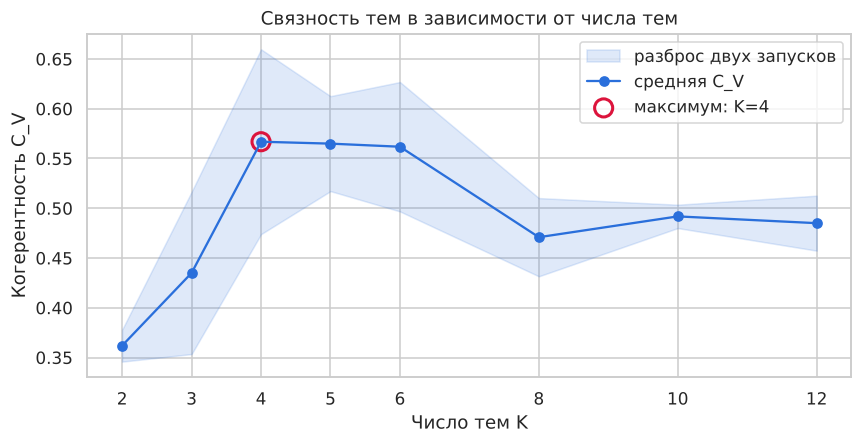

seed,7,42,среднее
K,,,
2,0.3780,0.3459,0.3619
3,0.5165,0.3535,0.4350
4,0.6597,0.4740,0.5669
5,0.6126,0.5172,0.5649
6,0.6268,0.4968,0.5618
8,0.5102,0.4316,0.4709
10,0.5035,0.4801,0.4918
12,0.5126,0.4574,0.4850


In [20]:
best_k = int(coh.loc[coh['mean'].idxmax(), 'K'])

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.fill_between(coh['K'], coh['min'], coh['max'], color='#2a6fdb', alpha=0.15, label='разброс двух запусков')
ax.plot(coh['K'], coh['mean'], marker='o', color='#2a6fdb', label='средняя C_V')
ax.scatter([best_k], [coh.loc[coh['K'] == best_k, 'mean']], s=140, facecolors='none', edgecolors='crimson',
           linewidths=2, label=f'максимум: K={best_k}')
ax.set_xticks(K_GRID)
ax.set_xlabel('Число тем K'); ax.set_ylabel('Когерентность C_V')
ax.set_title('Связность тем в зависимости от числа тем'); ax.legend()
plt.tight_layout(); plt.show()

display(coh_all.pivot(index='K', columns='seed', values='C_V').assign(среднее=coh.set_index('K')['mean']).round(4))

**Вывод по шагу 6.** Средняя C_V растёт от 0,362 при K=2 и 0,435 при K=3 до 0,567 при K=4, затем держится на плато (K=5: 0,565, K=6: 0,562) и падает при K от 8 и больше (0,471 при K=8, 0,492 при K=10, 0,485 при K=12). Максимум достигается при **K=4**.

Эту оценку нужно читать осторожно. Значения для K=4, 5 и 6 различаются меньше чем на 0,005, это в пределах шума. Сам шум большой: при одном и том же K два запуска с разной инициализацией различаются сильно (при K=4 получилось 0,474 и 0,660). Поэтому надёжно можно утверждать только, что 2 и 3 темы слишком мало, а после 6 связность падает. Внутри плато K=4 выбираю по трём причинам: это максимум средней когерентности, это самая простая модель из плато, а лучший отдельный запуск (0,660) тоже получен при K=4. Метки классов LDA не видел, но четыре темы по смыслу совпадают с четырьмя разделами новостей, это проверено в шаге 7.

In [21]:
K_OPT = best_k
best_seed = int(coh_all[coh_all['K'] == K_OPT].sort_values('C_V').iloc[-1]['seed'])   # лучший из двух запусков
lda_final = models[(K_OPT, best_seed)]
print(f'Выбрано K = {K_OPT}: средняя C_V = {coh.loc[coh["K"] == K_OPT, "mean"].iloc[0]:.4f}')
print(f'Дальше использую запуск с random_state={best_seed} (C_V = {coh_all[(coh_all["K"] == K_OPT) & (coh_all["seed"] == best_seed)]["C_V"].iloc[0]:.4f})')

Выбрано K = 4: средняя C_V = 0.5669
Дальше использую запуск с random_state=7 (C_V = 0.6597)


### 6.3 Интерактивная визуализация pyLDAvis

Слева темы показаны кругами на плоскости: чем ближе круги, тем больше у тем общих слов, размер круга это доля темы в корпусе. Справа для выбранной темы показаны её самые значимые слова: синяя полоска это частота слова в корпусе, красная его частота внутри темы. Ползунок lambda переключает ранжирование слов: при значении 1 важны просто частые слова темы, при меньших значениях выше поднимаются слова, характерные именно для этой темы.

In [22]:
import pyLDAvis
import pyLDAvis.gensim_models

pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(lda_final, corpus, dictionary, mds='mmds', sort_topics=False)
pyLDAvis.save_html(vis, 'lda_vis.html')      # то же самое отдельным файлом
vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.109216  0.077236       1        1  22.615300
1      0.102960 -0.136470       2        1  29.030363
2     -0.165340 -0.049879       3        1  28.583251
3     -0.046836  0.109113       4        1  19.771086, topic_info=          Term         Freq        Total Category  logprob  loglift
121  microsoft  1027.000000  1027.000000  Default  30.0000  30.0000
87        game  1350.000000  1350.000000  Default  29.0000  29.0000
28       stock   810.000000   810.000000  Default  28.0000  28.0000
390        oil  1252.000000  1252.000000  Default  27.0000  27.0000
359      price  1082.000000  1082.000000  Default  26.0000  26.0000
..         ...          ...          ...      ...      ...      ...
16        team   211.659421   921.166447   Topic4  -5.7222   0.1503
835       iraq   209.144069  1068.129152   Topic4  -5.7342  -0.0097
170      offer   183.304725   558.093259   Topic4  -5.8661   0.5076
213        win   201.950807  1425.100083   Topic4  -5.7692  -0.3330
87        game   182.540492  1350.408395   Topic4  -5.8702  -0.3802

[339 rows x 6 columns], token_table=      Topic      Freq    Term
term                         
147       1  0.026403  afghan
147       2  0.943892  afghan
147       3  0.019802  afghan
147       4  0.013201  afghan
1230      1  0.009684     amd
...     ...       ...     ...
35        4  0.027221     yen
546       1  0.233258    york
546       2  0.056607    york
546       3  0.571922    york
546       4  0.138589    york

[1021 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4])

**Как читать визуализацию.** Нумерация тем в pyLDAvis начинается с единицы, то есть Topic 1 на графике это тема 0 в таблице шага 7, и так далее. Параметр `sort_topics=False` сохраняет тот же порядок, что в модели. Для расчёта расстояний между темами использован метод `mmds`, потому что стандартный `pcoa` в моей версии библиотеки возвращает комплексные числа и ломает сохранение блокнота. Интерактивная версия также сохранена отдельным файлом `lda_vis.html`.

## 7. Интерпретация тем

Для каждой темы вывожу десять слов с наибольшим весом (в скобках вероятность слова в теме). Чтобы проверить, что темы имеют смысл, дополнительно считаю, какую долю корпуса занимает каждая тема и как документы с наибольшей вероятностью каждой темы распределены по настоящим классам AG News. Метки при обучении LDA не использовались, поэтому это независимая проверка.

In [23]:
doc_topics = np.array([[p for _, p in lda_final.get_document_topics(b, minimum_probability=0)] for b in corpus])
share = doc_topics.mean(axis=0)

for i in range(K_OPT):
    words = lda_final.show_topic(i, topn=10)
    print(f'Тема {i} (доля корпуса {share[i]:.1%})')
    print('   ', ', '.join(f'{w} ({p:.3f})' for w, p in words))

Тема 0 (доля корпуса 24.0%)
    game (0.014), win (0.011), season (0.008), world (0.006), team (0.006), night (0.006), run (0.005), victory (0.005), play (0.005), player (0.004)
Тема 1 (доля корпуса 27.9%)
    president (0.009), kill (0.009), iraq (0.008), bush (0.006), minister (0.006), official (0.006), leader (0.005), government (0.005), election (0.005), china (0.005)
Тема 2 (доля корпуса 28.0%)
    company (0.011), oil (0.011), price (0.010), stock (0.008), market (0.007), percent (0.007), rise (0.007), york (0.006), share (0.006), profit (0.006)
Тема 3 (доля корпуса 20.1%)
    microsoft (0.013), software (0.007), company (0.007), search (0.006), internet (0.006), security (0.005), service (0.005), test (0.005), web (0.005), computer (0.004)


In [24]:
dominant = doc_topics.argmax(axis=1)
ct = pd.crosstab(pd.Series(dominant, name='тема'), lda_df['category'], normalize='index').mul(100).round(1)
ct['документов'] = pd.Series(dominant).value_counts().sort_index().values
ct

category,Business,Sci/Tech,Sports,World,документов
тема,,,,,
0,7.8,11.5,75.7,5.0,4854
1,8.7,6.2,8.7,76.4,5585
2,61.4,34.0,1.1,3.6,5735
3,15.0,57.9,20.8,6.3,3816


**Названия и описания тем.** Четыре темы получаются чёткими, и каждая соответствует одному из разделов новостей.

- **Тема 0, «Спорт» (24,0% корпуса).** Слова `game`, `win`, `season`, `team`, `night`, `victory`, `play`, `player` описывают матчи, победы и сезоны. Среди документов, где эта тема главная, 75,7% относятся к классу Sports.
- **Тема 1, «Политика и международные события» (27,9%).** Слова `president`, `kill`, `iraq`, `bush`, `minister`, `official`, `government`, `election`, `china` задают мировую политику, выборы и военные конфликты. 76,4% документов этой темы из класса World.
- **Тема 2, «Экономика и финансы» (28,0%).** Слова `company`, `oil`, `price`, `stock`, `market`, `percent`, `rise`, `share`, `profit` описывают рынки, цены на нефть и корпоративные результаты. 61,4% документов из Business, а ещё 34,0% из Sci/Tech: это финансовые новости технологических компаний.
- **Тема 3, «Технологии и интернет-компании» (20,1%).** Слова `microsoft`, `software`, `search`, `internet`, `security`, `service`, `web`, `computer` говорят о программном обеспечении, поиске и безопасности. 57,9% документов из Sci/Tech, остальное распределено между Sports (20,8%), Business (15,0%) и World (6,3%). Заметная доля Sports в этой теме выглядит неожиданно, причину я не проверяла.

**Проверка.** Для трёх тем из четырёх документы доминирующего класса составляют большинство (76%, 76% и 61%), для технологической темы 58%. Тема 2 забирает вместе Business и часть Sci/Tech, потому что слова `company`, `share`, `profit` одинаково характерны для обоих классов. Это та же граница, на которой ошибался классификатор в шаге 3 (Business и Sci/Tech путаются чаще всего).

Ограничения: модель обучена на выборке из 20 000 документов, а не на всех 120 000, результат LDA зависит от случайной инициализации (см. шаг 6), а слово `world` попало в тему про спорт, возможно, из названий турниров вроде World Cup, но это я не проверяла.

## Итоги

- **Векторизация.** BoW и TF-IDF имеют одинаковую размерность 42 500 (словарь только на Train, `min_df=2`), без отсечения редких слов она была бы 72 749. Матрицы заполнены на 0,072%.
- **Классификация.** TF-IDF плюс LinearSVC: Macro F1 0,9225 (Precision 0,9226, Recall 0,9227). Naive Bayes: Macro F1 0,9086. Чаще всего путаются Business и Sci/Tech (7,0% и 6,2%). Классы сбалансированы, поэтому Accuracy здесь равна Macro Recall, а её недостаток в том, что она скрывает различия между классами (F1 от 0,894 у Business до 0,971 у Sports).
- **Поиск.** Инвертированный индекс по 120 000 документам: 60 407 термов. BM25 на трёх запросах вернул в топ-5 только документы нужного раздела.
- **Тематическое моделирование.** По C_V выбрано K=4 (средняя C_V 0,567), хотя K=4, 5 и 6 статистически почти не различимы. Темы: спорт, политика и международные события, экономика и финансы, технологии. Они совпадают с четырьмя разделами новостей на 58-76%.